<a href="https://colab.research.google.com/github/kyrylo-moiseyev/ITR_3/blob/main/ITR_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import
import networkx as nx             # Для створення та побудовы графів
import matplotlib.pyplot as plt   # Для відображення графу
import math as m                  # Для знаходження кореня, модулю і тд
import numpy as np                # Робота з масивами
import random as r                # Рандимізування даних
import time as t                  # Визначення часу

import torch
import torch.nn as nn
import torch.nn.functional as F   # Робота з нейронною мережею
import torch.optim as optim
import torchvision

In [ ]:

print("Кількість вершин:") #Задаємо кількість вершин
try:
    N = int(input())       #Принекоректному\пустому вводі, маємо 25 вершин
except:
    N=25

block = m.ceil(m.sqrt(N))  #Обчислюэмо розмір нашого квадрату (block x block)
while(1):
    print("Кількість ребер на видалення:")    #Задаємо кількість видалених ребер
    on_delete = int(input())
    if on_delete<=N-(block*2-1):              #Перевіряемо чи взагалі можливо видалити стільки
        break                                 #ребер і виконати завдання
    print("Неможливо виконати завдання з такою кількістю видалень, макс ", N-(block*2-1))

node_del = block-N                            #Обраховуємо скільки ребер потрібно видалити
mas = []                                      #Масив для координат для графу
el = 0
size_set = 0.09

Кількість вершин:
40
Кількість ребер на видалення:
30
Неможливо виконати завдання з такою кількістю видалень, макс  27
Кількість ребер на видалення:
20


In [ ]:
class Graph:                                 # Клас графу
    def __init__(self, vertex):              # Визначення пареметр
        self.V = vertex
        self.graph = []

    def add_edge(self, u, v, w):               # Додавання додавання
        self.graph.append([u, v, w])           # ребер


    def search(self, parent, i):               # Пошук
        if parent[i] == i:
            return i
        return self.search(parent, parent[i])

    def apply_union(self, parent, rank, x, y): # Рангування
        xroot = self.search(parent, x)
        yroot = self.search(parent, y)
        if rank[xroot] < rank[yroot]:
            parent[xroot] = yroot
        elif rank[xroot] > rank[yroot]:
            parent[yroot] = xroot
        else:
            parent[yroot] = xroot
            rank[xroot] += 1


    def kruskal(self):                         # Реалізація алгоритму Крускала
        result = []
        i, e = 0, 0
        self.graph = sorted(self.graph, key=lambda item: item[2])
        parent = []
        rank = []
        for node in range(self.V):
            parent.append(node)
            rank.append(0)
        while e < self.V-1:
            u, v, w = self.graph[i]
            i = i+1
            x = self.search(parent, u)
            y = self.search(parent, v)
            if x != y:
                e = e + 1
                result.append((u, v))
                self.apply_union(parent, rank, x, y)
        return self.graph,result             # повертає загальну кількість ребер, та вже доданих у граф

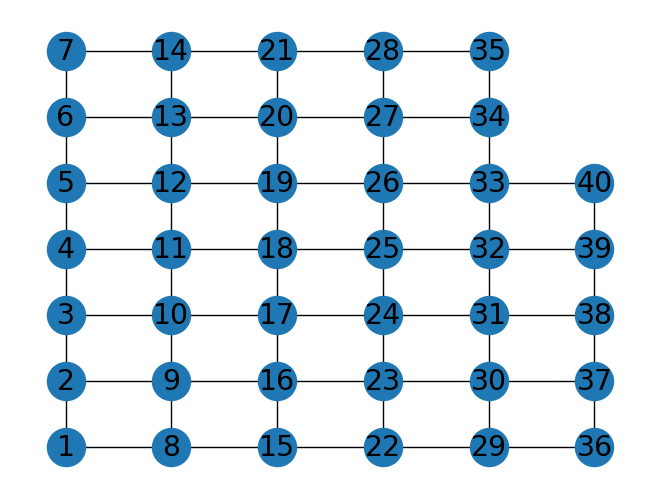

In [ ]:
for i in range(block):
    for j in range(block):
        mas.append((i*5,j*5))        # Створюємо масив з координатами розміром (block x block)
        el += 1
        if(el == N):
            break
    if(el == N):
        break

edges_mas = []
G=nx.Graph()                         # Створюємо змінну графу
g = Graph(N)                         # Створюємо клас графу
for i in range(N):
    G.add_node(i+1,pos=mas[i])       # Створюємо вершини графу

for i in range(N-1):
    if(i%block!=block-1):
        G.add_edge(i+1,i+2)
        edges_mas.append((i,i+1))
        g.add_edge(i,i+1, np.random.randint(0,1000))      # Прокладаємо ребра між вершинами як у класі, так і на графі
    if(i+block+1 <=N):
        G.add_edge(i+1,i+block+1)
        g.add_edge(i,i+block, np.random.randint(0,1000))
        edges_mas.append((i,i+block))


pos=nx.get_node_attributes(G,'pos')
nx.draw(G,pos,node_size=30000/N, with_labels = True, font_size = 24-(size_set*N))    # Будуємо та відображаемо графік
plt.show()


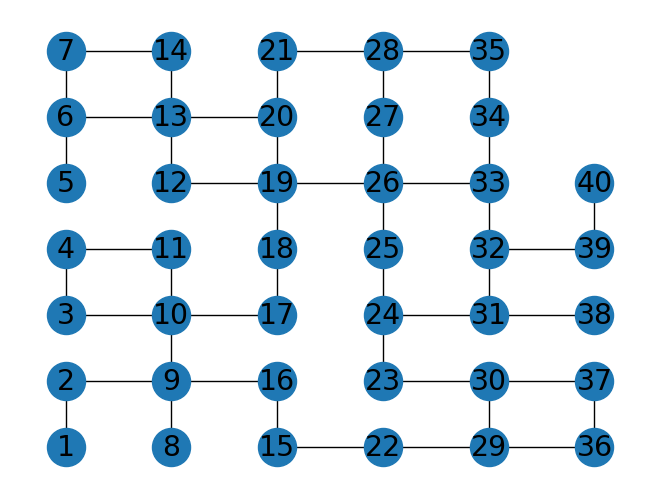

In [ ]:
all_e, mas_2 = g.kruskal()                      # Застосовуэмо алгоритм Крускала

new_edges_mas = []
for i in range(len(edges_mas)):
    new_edges_mas.append(edges_mas[i])

r.shuffle(new_edges_mas)

edd = 0                                         # Змінна для відслідкуванні кількості ребер
while len(mas_2) < len(all_e)-on_delete:        # Поки кількість ребер не відповідає зазначеній на початку кількості
    if(new_edges_mas[edd] not in mas_2):            # Якщо ребро ще не відображене, то додаємо його
        mas_2.append(new_edges_mas[edd])
    edd = edd+1



for i in range(len(new_edges_mas)):
    try:
         if new_edges_mas[i] not in mas_2:
            G.remove_edge(new_edges_mas[i][0]+1, new_edges_mas[i][1]+1)          # Додаємо ребра на граф
    except:
        pass
nx.draw(G,pos,node_size=30000/N, with_labels = True, font_size = 24-(size_set*N))
plt.show()                                                           # Відображаємо граф                                                        # Відображаємо граф


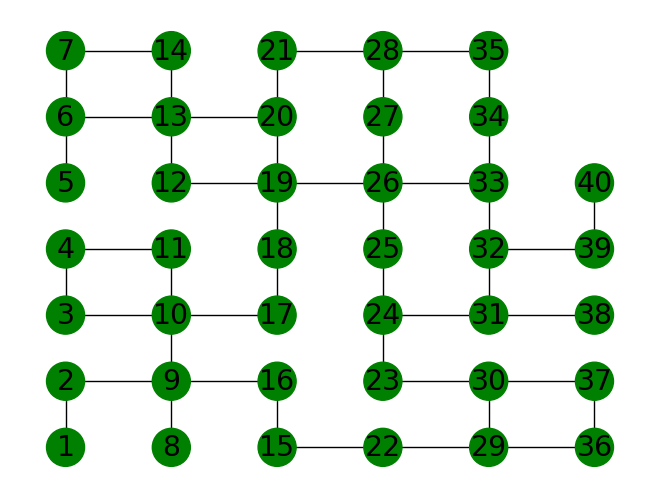

In [ ]:
color_map = []

for i in range(len(G)):
    color_map.append('green')


nx.draw(G,pos,node_color=color_map,node_size=30000/N, with_labels = True, font_size = 24-(size_set*N))
plt.show()

In [ ]:
while(1):
    print('Введіть початковий пункт: ')
    start = int(input())
    if(start>len(pos) or start <=0):
        print("У графі всього 1-", len(pos), " вершин")
    else:
        break
while(1):
    print('Введіть кінцевий пункт: ')
    end = int(input())
    if(end>len(pos) or end <=0):
        print("У графі всього 1-", len(pos), " вершин")
    else:
        break




Введіть початковий пункт: 
1
Введіть кінцевий пункт: 
40


In [ ]:
def find_pos(node):
    for i in range(len(pos)):                   # знаходження позиції певної вершини
        if(i+1==node):
            return pos[i+1]

def find_edges(now):
    pos_i=[]
    for i in range(len(mas_2)):                  # знаходимо та повертаємо ребра графу, що
        if(now-1 in mas_2[i]):                   # тягнуться від вершини нашого перебування
            pos_i.append(mas_2[i])
    return pos_i

def find_mas_pos(mas, now):
    mas_pos = []
    edges = []
    for i in range(len(mas)):
        if mas[i][0] == now-1:
            mas_pos.append(find_pos(mas[i][1]+1))  # Знаходимо до куди тягнуться графи та їх
            edges.append(mas[i][1])                # позиції
        else:
            mas_pos.append(find_pos(mas[i][0]+1))
            edges.append(mas[i][0])
    return mas_pos, edges

def fun_estimate(mas_edges):                        # проводимо оцінку всіх вершин
    estimate = []
    for i in range(len(mas_edges)):
        estimate.append( (mas_edges[i][0]-find_pos(end)[0])**2 + (mas_edges[i][1]-find_pos(end)[1])**2)
    return estimate

def pos_min(x):                           # обраховуємо найближчий до кінцевої точки вершину
    pos=[]
    for i in range(len(x)):
        if x[i] == min(x):
            pos.append(i)
    return pos

def check_exception(mas_edges, edgesss, x):
    stop = len(edgesss)
    i=0
    while stop > 0:
        #print(len(edgesss),'--',edgesss[i],'--')      # функція для перевірки пройденого шляху чи тупіку
        if edgesss[i] in x:
            mas_edges.pop(i)
            edgesss.pop(i)
            i-=1
        i+=1
        stop-=1
    return mas_edges, edgesss

100%|██████████| 9.91M/9.91M [00:00<00:00, 43.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.05MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.76MB/s]


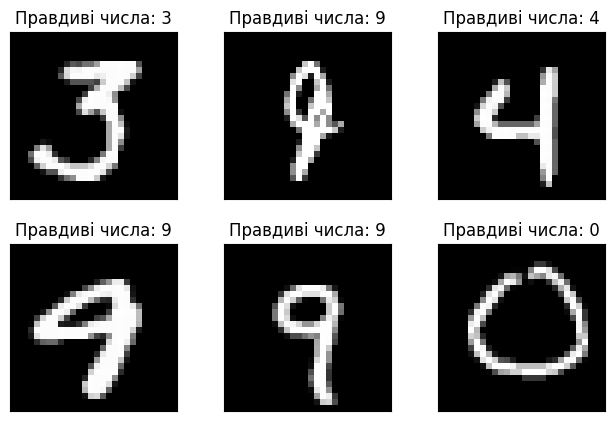

In [ ]:
n_epochs = 3
batch_size_train = 64
batch_size_test = 1000                      # Налаштування параметрів навчання
learning_rate = 0.01
momentum = 0.5
log_interval = 10

random_seed = 1                             # Визначення сіду
torch.backends.cudnn.enabled = False        # Відключення налаштування недетермінованих алгоритмів
torch.manual_seed(random_seed)

train_loader = torch.utils.data.DataLoader(
   torchvision.datasets.MNIST('/files/', train=True, download=True,
   transform=torchvision.transforms.Compose([                            # Завантаження тренувальної вибірки
                                             torchvision.transforms.ToTensor(),
                                             torchvision.transforms.Normalize((0.1307,), (0.3081,))
                                            ])),
   batch_size=batch_size_train, shuffle=True)


test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=False, download=True,
  transform=torchvision.transforms.Compose([                             # Завантаження тестової вибірки
                                            torchvision.transforms.ToTensor(),
                                            torchvision.transforms.Normalize((0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)


examples = enumerate(test_loader)                           # Розбиваємо наші тестові данні на зміння для
batch_idx, (example_data, example_targets) = next(examples) # більш зручного використання

n = 6
fig = plt.figure()
for i in range(n):
  plt.subplot(2,3,i+1)                                      # Будуємо вибірку з n рукописних цифр та цифру
  plt.tight_layout()                                        # якою вони є (точно визначена)
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Правдиві числа: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])


In [ ]:
class Net(nn.Module):                                   # Клас для нашої нейронної мережі
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)    # Спочатку йдуть 2 згорточні
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
        self.conv2_drop = nn.Dropout2d()                # Далі робимо дропаут для запобігання перенавчання
        self.fc1 = nn.Linear(320, 50)                   # І в кінці 2 лінійних шари
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):                                           # Функція класу навчання моделі
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2_drop(self.conv2(x)), 2)) # Використовуємо вище описані функції torch
        x = x.view(-1, 320)                                         # разом з активаціями relu та додаткового дропаут
        x = F.relu(self.fc1(x))
        x = F.dropout(x, training=self.training)
        x = self.fc2(x)
        return F.log_softmax(x)                              # Повертаэмо результат пропущений через софтмакс



In [ ]:
def train(epoch):                                  # Функція тренування
  network.train()                                  # Навчаємо модель
  for batch_idx, (data, target) in enumerate(train_loader):
    optimizer.zero_grad()
    output = network(data)
    loss = F.nll_loss(output, target)              # Отримуємо втрати
    loss.backward()                                # Зворотнє навчання
    optimizer.step()                               # Переоцінка моделі і повертання втрати
    if batch_idx % log_interval == 0:
      print('Епоха: {} [{}/{} ({:.0f}%)]\tВтрати: {:.6f}'.format(  # Виводимо інформацію про номер епохи, кількість
        epoch, batch_idx * len(data), len(train_loader.dataset),       # пройдених екземплярів (і в процентах), а також
        100. * batch_idx / len(train_loader), loss.item()))            # втрати після деякого проміжку (пакету)

      train_losses.append(loss.item())                                 # Запам'ятовуємо втрати

      train_counter.append(
        (batch_idx*64) + ((epoch-1)*len(train_loader.dataset)))        # Запам'ятовуємо раніше показану інформацію

      torch.save(network.state_dict(), 'model.pth')                    # Зберігаємо отримані дані
      torch.save(optimizer.state_dict(), 'optimizer.pth')


def test():                             # Функція тестування
  network.eval()                        # Переключання деяких шарів моделі для навчання
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      output = network(data)
      test_loss += F.nll_loss(output, target, size_average=False).item()
      pred = output.data.max(1, keepdim=True)[1]                    # Тут ми тестуємо нашу модель
      correct += pred.eq(target.data.view_as(pred)).sum()           # та отримуємо цілісну характеристику, наприклад
  test_loss /= len(test_loader.dataset)                             # загальна кількість правильно передбачених цифр,
  test_losses.append(test_loss)                                     # втрати, точність і тд
  print('\nТестувальний сет: Avg. Втрати: {:.4f}, Точність: {}/{} ({:.0f}%)\n'.format(    # і тут виводимо результат
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))


network = Net()                             # Використовуэмо наш клас для створення екземпляру нашої мережі
optimizer = optim.SGD(network.parameters(),
                      lr=learning_rate,     # Налаштовуємо оптимізатор та заповнюємо раніше створеними змінними
                      momentum=momentum)

train_losses = []
train_counter = []                          # Створємо масиви для подальшого використання
test_losses = []
test_counter = [i*len(train_loader.dataset) for i in range(n_epochs + 1)]

test()
for epoch in range(1, n_epochs + 1):     # Прогоняємо наш алгоритм по кількості бажаних епох
  train(epoch)
  test()

/tmp/ipykernel_2159/3944130364.py:17: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return F.log_softmax(x)                              # Повертаэмо результат пропущений через софтмакс
/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3178: UserWarning: size_average and reduce args will be deprecated, please use reduction='sum' instead.
  reduction = _Reduction.legacy_get_string(size_average, reduce)



Тестувальний сет: Avg. Втрати: 2.3096, Точність: 924/10000 (9%)

Епоха: 1 [0/60000 (0%)]	Втрати: 2.325928
Епоха: 1 [640/60000 (1%)]	Втрати: 2.287777
Епоха: 1 [1280/60000 (2%)]	Втрати: 2.281435
Епоха: 1 [1920/60000 (3%)]	Втрати: 2.243744
Епоха: 1 [2560/60000 (4%)]	Втрати: 2.264606
Епоха: 1 [3200/60000 (5%)]	Втрати: 2.240564
Епоха: 1 [3840/60000 (6%)]	Втрати: 2.153203
Епоха: 1 [4480/60000 (7%)]	Втрати: 2.211479
Епоха: 1 [5120/60000 (9%)]	Втрати: 2.056642
Епоха: 1 [5760/60000 (10%)]	Втрати: 2.010619
Епоха: 1 [6400/60000 (11%)]	Втрати: 2.008978
Епоха: 1 [7040/60000 (12%)]	Втрати: 1.867195
Епоха: 1 [7680/60000 (13%)]	Втрати: 1.755029
Епоха: 1 [8320/60000 (14%)]	Втрати: 1.617570
Епоха: 1 [8960/60000 (15%)]	Втрати: 1.411560
Епоха: 1 [9600/60000 (16%)]	Втрати: 1.595001
Епоха: 1 [10240/60000 (17%)]	Втрати: 1.259282
Епоха: 1 [10880/60000 (18%)]	Втрати: 1.326851
Епоха: 1 [11520/60000 (19%)]	Втрати: 1.236279
Епоха: 1 [12160/60000 (20%)]	Втрати: 1.041675
Епоха: 1 [12800/60000 (21%)]	Втрати: 1.1270

/tmp/ipykernel_2159/3944130364.py:17: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return F.log_softmax(x)                              # Повертаэмо результат пропущений через софтмакс


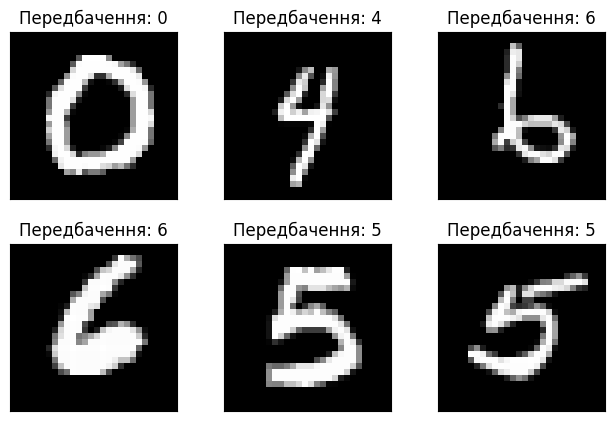

In [ ]:
with torch.no_grad():
  output = network(example_data)

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i+50][0], cmap='gray', interpolation='none')
  plt.title("Передбачення: {}".format(
    output.data.max(1, keepdim=True)[1][i+50].item()))
  plt.xticks([])
  plt.yticks([])

Шлях:
1(40км\ч) -> 2(40км\ч) -> 9(50км\ч) -> 10(40км\ч) -> 17(50км\ч) -> 18(80км\ч) -> 19(80км\ч) -> 26(80км\ч) -> 33(50км\ч) -> 32(30км\ч) -> 39(70км\ч) -> 40

Кількість кроків: 11
Пошук зайняв: 0.022591829299926758
Середня швидкість: 55.45454545454545


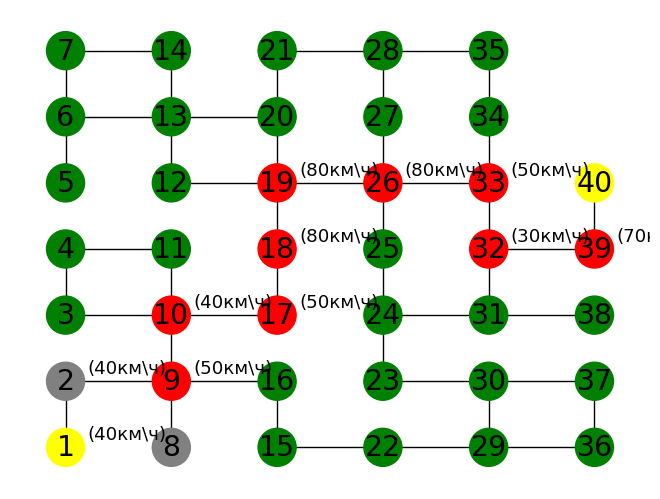

In [ ]:
start_time = t.time()
n_steps = 0
color_map = []
for node in G:                       # спочатку фарбуємо наш граф у зелений
    color_map.append('green')

shift_from_max = [-1.3*N**0.3,1]
shift_from_min = [1*N**0.01,1]
if start > end:
    shift = shift_from_max           # Визначаэмо зміщення у випадку шляху зліва направо чи навпаки
else:
    shift = shift_from_min

shifted_pos = pos.copy()             # Додаэмо зміщення до координат наших вершин
for k in pos.keys():
    shifted_pos[k] = (pos[k][0]+shift[0],pos[k][1]+shift[1])

mean_speed = []                      # Масив по якому ми потім оьрахуемо середню швидкість
labels = {}                          # Сдовник назв, які ми потім виведемо поряд з вершинами
deadlock = []
visited = []                         # створюємо два масиви: для відвіданих вершин та для тупикових
now = start                          # створюємо змінну поточної вершини перебування
last_now = -1
print('Шлях:')
while (1):                           # починається основний цикл пошуку шляху
    corner=False
    speed = 0

    print(now,end='')                # виводимо поточну вершину

    if now-1 not in visited:         # якщо її ще не має у відвіданих, то додаємо її
        visited.append(now-1)

    if now == end:                   # якщо наша вершина - це наш кінець, то завершуємо програму
        break



    while speed <=20:                # За умовою нам потрібна швидкість > 20
        speed = output.data.max(1, keepdim=True)[1][r.randint(0,999)].item()*10  # Беремо рандомну фотографію цифри та
                                                                                 # визначаємо її за допомогою згортки

    print('({}км\\ч)'.format(speed),'-> ',end='')               # Разом з вершиної виводми швидкість на цьому шляху
    mean_speed.append(speed)                                    # Додаємо швидкість для подальшого визначення середньої
    labels[now] = '({}км\\ч)'.format(speed)                     # Додаємо назву швидкості для відображення на графі




    n_steps += 1
    mas_edges, edgesss = find_mas_pos(find_edges(now), now)    # отримуємо масив вершин та ребер
    mas_edges, edgesss = check_exception(mas_edges, edgesss, deadlock) # перевіряємо масив на тупіки та видаляємо їх

    adge_estim = []                  # Створюємо масив оцінок сміжних графів
    for i in range(len(edgesss)):

        # Обраховує масив вершин та ребер сміжних графів
        ex_mas_edges, ex_edgesss = find_mas_pos(find_edges(edgesss[i]+1), edgesss[i]+1)

        ## Сповіщення сміжного графу
        #print('Сміжна ершина перебування:',edgesss[i]+1, 'Позиції сміжні:', ex_mas_edges,'Сміжні вершини:', ex_edgesss, 'Надлежить видаленню?: ',len(ex_mas_edges)==1)

        ex_save_mas_edges=np.copy(ex_mas_edges[0])      # резервно зберігаємо наші дані
        ex_save_edgesss= np.copy(ex_edgesss[0])

        if len(ex_mas_edges)==1:                 # якщо після очищення ми отримали пустий масив, то вершина є тупікова
            if edgesss[i]+1-1 not in deadlock and edgesss[i]+1 != end:
                deadlock.append(edgesss[i]+1-1)        # додаємо вершину до тупікових
                #print('\t\tWe delete',edgesss[i]+1)   ### Сповіщення про видалення графу
            ex_mas_edges.append(ex_save_mas_edges)
            ex_edgesss.append(ex_save_edgesss)

        estimat = fun_estimate(ex_mas_edges)                            # оцінюємо наші вершини

        # Обраховуємо оцінку для сміжних графів, якщо вони не тягнуться до вершини перебування чи до вершини
        # яку ми тільки що залишили

        if edgesss[i]+1 != now and edgesss[i]+1 != last_now:
            adge_estim.append(estimat)

        #print("Сміжний граф", edgesss[i]+1,"Оцінка сміжного графу", estimat) ## Сповіщення оцінки сміжного графу

    # Обраховуємо наш граф після перевірки сміжних графів

    mas_edges, edgesss = find_mas_pos(find_edges(now), now)    # отримуємо масив вершин та ребер
    mas_edges, edgesss = check_exception(mas_edges, edgesss, deadlock) # перевіряємо масив на тупіки та видаляємо їх

    ## Сповіщення оцінки основного графу після дослідження сміжних графів

    #print('Вершина перебування:',now,'Минула вершина:',last_now,'Позиції:',mas_edges,'Сміжні вершини:',edgesss)
    #print('Глибокі графи:', adge_estim)

    if len(mas_edges)!=0:
        save_mas_edges=np.copy(mas_edges[0])      # резервно зберігаємо наші дані
        save_edgesss= np.copy(edgesss[0])

    if len(mas_edges)==1:                 # якщо наш граф має лише одне ребро, а також, оскільки програма досі працює,
       corner=True                        # не є кінцем, тож вершина - тупікова, запам'ятовуємо це

    mas_edges, edgesss = check_exception(mas_edges, edgesss, visited)  # очищуємо вершину від відвіданих вершин

    if len(mas_edges)==0:                 # якщо після очищення ми отримали пустий масив, то вершина є тупікова
        if now-1 not in deadlock:         # і невідвіданих вершин поруч немо, тож повертаємо резервні дані і
            deadlock.append(now-1)        # додаємо вершину до тупікових
        mas_edges.append(save_mas_edges)
        edgesss.append(save_edgesss)

    estimat = fun_estimate(mas_edges)                # оцінюємо наші вершини

    #print('Оцінка основного граф:', estimat)        ## Сповіщення оцінки основного графу

    if len(adge_estim) != 0:
        for i in range(len(estimat)):
            estimat[i] += min(adge_estim[i])         # Додаємо мінімальну оцінку серед сміжних графів до основного

    pos_min_el = pos_min(estimat)                                # шукаємо найнижчу оцінку

    new_now = edgesss[pos_min_el[r.randint(0,len(pos_min_el)-1)]]  # якщо вершин з найнижчою оцінкою декілька,
                                                                   # то обираємо рандомНУ СЕРЕД НИХ

    if corner:
       if now-1 not in deadlock:              # видаляємо раніше запам'ятовану вершину
            deadlock.append(now-1)

    last_now = now
    now = new_now+1             # робимо крок у вибрану вершину і повертаємось у початок


for i in range(len(visited)):
    color_map[visited[i]] = 'red'         # фарбуємо відвідані вершини у червоний

for i in range(len(deadlock)):
    color_map[deadlock[i]] = 'grey'       # фарбуємо тупикові вершини у сірий

color_map[start-1] = 'yellow'
color_map[end-1] = 'yellow'               # для зручності помічаємо жовтим початок та кінець

print("\n\nКількість кроків:",n_steps)     # Кількість циклів алгоритму, а значить кроків
print("Пошук зайняв:",t.time()-start_time) # Віднімаючи від часу кінця час початку - отримуємо час роботи алгоритму
print('Середня швидкість:',sum(mean_speed)/len(mean_speed))
nx.draw(G,pos,node_color=color_map,node_size=30000/N, with_labels = True, font_size = 24-(size_set*N)) # виводимо граф

# Будуємо надписи поряд з вершинами
nx.draw_networkx_labels(G, shifted_pos, labels=labels,font_size = 24-(size_set*N**1.3), horizontalalignment="left")
plt.show()